In [ ]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import  matplotlib.pyplot as plt 
from sklearn.preprocessing import *
from sklearn.compose  import ColumnTransformer
from sklearn.pipeline import make_pipeline,Pipeline
from sklearn.model_selection  import *
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *

## Table of contents 
1. Checking the missing and unique values
2. EDA
3. Checking skewness and applying a transformation and scaling
4. Model building with cross-validation
5. Hyperparameter tuning and comparison of models
6. Getting relevant metrics

In [2]:
data = pd.read_csv("data/bedtime_screentime_sleep_debt.csv")
data =  data.drop(columns=['user_id'])
data =  data[data['gender'] !=  'Non-Binary']
print("data shape: ",data.shape )
data.head()


data shape:  (8252, 17)


,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
4,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt
5,23,Male,Healthcare / Shift Worker,Intermediate,76,TikTok / Reels,39,0,136,42,50.6,5.87,21.4,17.5,4,5.0,Moderate Debt


### 1) Checking missing values and Unique values 

In [3]:
print("Missing values : \n",data.isnull().mean() * 100)
print("....")

df =  data.copy()
encoders = {}

for x in data.columns :
    le =  LabelEncoder()
    if data[x].dtype in ['O',"string"]:
        print(f"{x} : {data[x].unique()}")
        df[x] =  le.fit_transform(data[x])
        encoders[x] =  le 


df.head()

Missing values : 
 age                         0.0
gender                      0.0
occupation_type             0.0
chronotype                  0.0
bedtime_phone_minutes       0.0
primary_bedtime_app         0.0
screen_brightness_pct       0.0
blue_light_filter_active    0.0
caffeine_post_5pm_mg        0.0
physical_activity_min       0.0
sleep_latency_min           0.0
total_sleep_hours           0.0
deep_sleep_pct              0.0
rem_sleep_pct               0.0
morning_alarm_snoozes       0.0
next_day_fatigue_score      0.0
sleep_debt_category         0.0
dtype: float64
....
gender : ['Female' 'Male']
occupation_type : ['Healthcare / Shift Worker' 'Student' 'Remote Tech'
 'Freelance / Creative' 'Corporate 9-to-5']
chronotype : ['Intermediate' 'Night Owl' 'Morning Lark']
primary_bedtime_app : ['Instagram / Reddit' 'YouTube' 'TikTok / Reels' 'News / Reading'
 'Streaming (Netflix/Hulu)' 'Messaging / Chat']
sleep_debt_category : ['Severe Sleep Debt' 'Moderate Debt' 'Optimal Recovery' 'Mil

,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,29,0,2,0,179,0,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,3
1,58,0,4,0,163,5,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,3
2,41,0,2,2,100,4,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,3
4,23,0,2,0,27,4,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,1
5,23,1,2,0,76,4,39,0,136,42,50.6,5.87,21.4,17.5,4,5.0,1


### 2)  EDA 

<Axes: xlabel='sleep_debt_category', ylabel='age'>

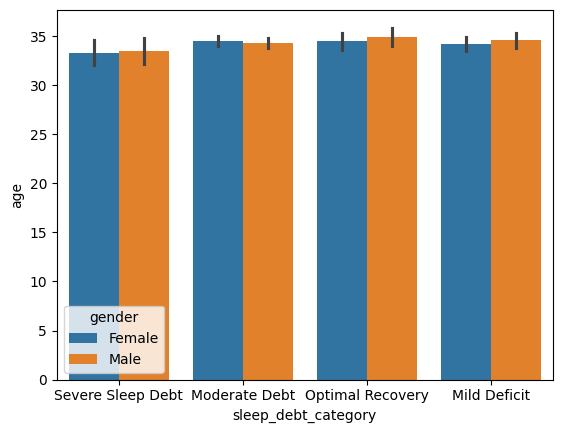

In [4]:
sns.barplot(data=data,x="sleep_debt_category",y="age",hue="gender")

<Axes: xlabel='age', ylabel='Density'>

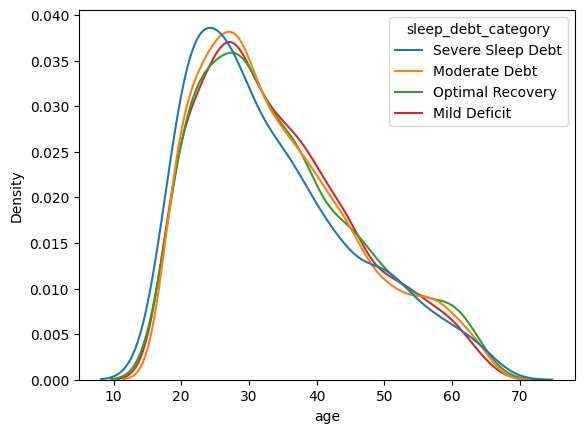

In [5]:
sns.kdeplot(x=data["age"],hue=data["sleep_debt_category"],common_norm=False)

<Axes: xlabel='bedtime_phone_minutes', ylabel='Density'>

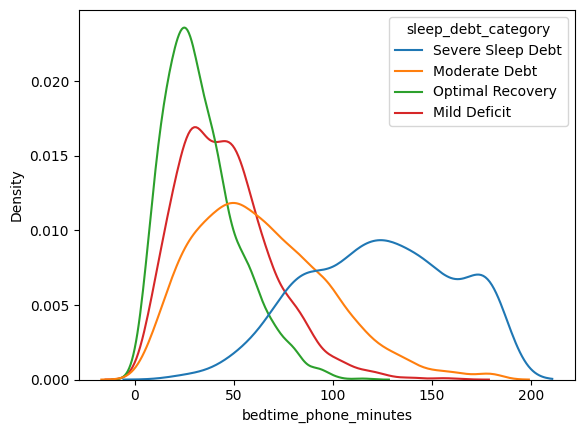

In [6]:
sns.kdeplot(x=data['bedtime_phone_minutes'],hue=data['sleep_debt_category'],common_norm=False)

<Axes: xlabel='caffeine_post_5pm_mg', ylabel='Density'>

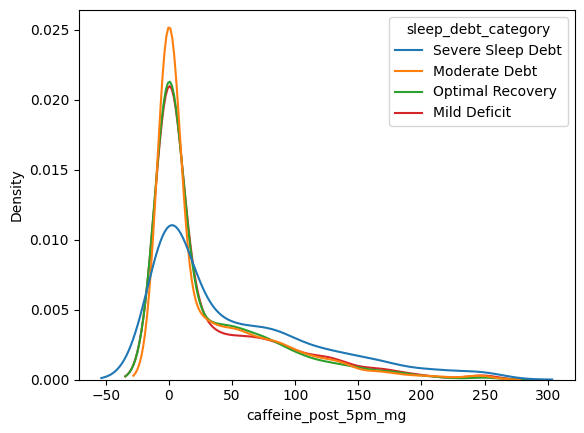

In [7]:
sns.kdeplot(x=data['caffeine_post_5pm_mg'],hue=data['sleep_debt_category'],common_norm=False)

### 3) checking skewness and applying transformations and scaling 

In [8]:
for x in df.columns :
    if str(df[x].dtype) in ['int32','int64','float64']:
        print(f"{x} :" ,df[x].skew())

age : 0.6854498347230256
gender : 0.10729905196693884
occupation_type : 0.012128300724586651
chronotype : 0.32466187210034936
bedtime_phone_minutes : 1.0307574756435067
primary_bedtime_app : -0.4319239844496031
screen_brightness_pct : -0.0031651152905895815
blue_light_filter_active : 0.12825505237074292
caffeine_post_5pm_mg : 1.7623836491078926
physical_activity_min : 0.2564238913291787
sleep_latency_min : 0.9768629985135855
total_sleep_hours : -0.16325080384626645
deep_sleep_pct : -0.262657160407715
rem_sleep_pct : -0.11857968900757027
morning_alarm_snoozes : 0.3444130977129651
next_day_fatigue_score : 0.7455622194182601
sleep_debt_category : 0.6374416479438142


In [9]:
df.head()

,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,29,0,2,0,179,0,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,3
1,58,0,4,0,163,5,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,3
2,41,0,2,2,100,4,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,3
4,23,0,2,0,27,4,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,1
5,23,1,2,0,76,4,39,0,136,42,50.6,5.87,21.4,17.5,4,5.0,1


In [10]:
skew_scale =  ['age','bedtime_phone_minutes','caffeine_post_5pm_mg','sleep_latency_min','next_day_fatigue_score']
scale =  ['screen_brightness_pct','physical_activity_min','total_sleep_hours','deep_sleep_pct','rem_sleep_pct']
ohe_cols = ['gender', 'occupation_type', 'chronotype' , 'primary_bedtime_app','morning_alarm_snoozes','blue_light_filter_active']

pipe =  Pipeline([
    ("step1",FunctionTransformer(func=np.log1p,feature_names_out="one-to-one")),
    ("step2",StandardScaler())
])


ct =  ColumnTransformer(transformers=[
    ("ct1",pipe,skew_scale),
    ("ct2",StandardScaler(),scale),
    ("ct3",OneHotEncoder(),ohe_cols)
],remainder="passthrough")


x =  df.drop(columns='sleep_debt_category')
y =  df['sleep_debt_category']
x_train,x_test,y_train,y_test =  train_test_split(x,y)

x_train_ct = ct.fit_transform(x_train)
x_test_ct =  ct.transform(x_test)


print(x_train_ct)




[[-1.18616651 -1.32636072 -0.83546369 ...  0.          0.
   1.        ]
 [-1.32489762  0.34293946  0.60740109 ...  0.          1.
   0.        ]
 [ 0.03370225  1.77813368 -0.83546369 ...  0.          0.
   1.        ]
 ...
 [-1.47008361 -0.500689    1.09696915 ...  0.          1.
   0.        ]
 [-0.46272849  0.64333467  1.12805712 ...  0.          0.
   1.        ]
 [ 0.69318442  0.21888103 -0.83546369 ...  0.          0.
   1.        ]]


### 4) model building via cross validation 

In [11]:
skfold =  StratifiedKFold()
model_rf =  RandomForestClassifier()

cross_model =  cross_validate(model_rf, x_train_ct, y_train, cv=skfold,
                        scoring=["accuracy", "f1_macro", "recall_macro", "precision_macro"])

for m in cross_model:
    print(f"{m} : ",cross_model[m].mean())

fit_time :  0.7053915023803711
score_time :  0.02984609603881836
test_accuracy :  0.9978997078501717
test_f1_macro :  0.9967503405471069
test_recall_macro :  0.9978258754327852
test_precision_macro :  0.995745504083548


### 5)  hyper parameter tuning and model comparison 

In [18]:
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
}

model_rf =  RandomForestClassifier()
gsv_rf =  GridSearchCV(model_rf,rf_param_grid)
gsv_rf.fit(x_train_ct,y_train)
print("Best score :",gsv_rf.best_score_)
print("best params :",gsv_rf.best_params_)
print("Best Estimator :",gsv_rf.best_estimator_)


# model_lr =  LogisticRegression()
# lr_param_grid = [
#     {'penalty':['l1','l2','elasticnet'],
#     'C' : np.logspace(-4,4,20),
#     'solver': ['lbfgs','newton-cg','liblinear','sag','saga'],
# }
# ]
# gsv_lr =  GridSearchCV(model_lr,lr_param_grid)
# gsv_lr.fit(x_train_ct,y_train)

# print("Best score :",gsv_lr.best_score_)
# print("best params :",gsv_lr.best_params_)
# print("Best Estimator :",gsv_lr.best_estimator_)

Best score : 0.9987075928917608
best params : {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
Best Estimator : RandomForestClassifier(min_samples_split=5, n_estimators=200)


### 6)  getting relevant metrics 
-  feature importance 
-  classification report 
- roc_auc_curve / score 

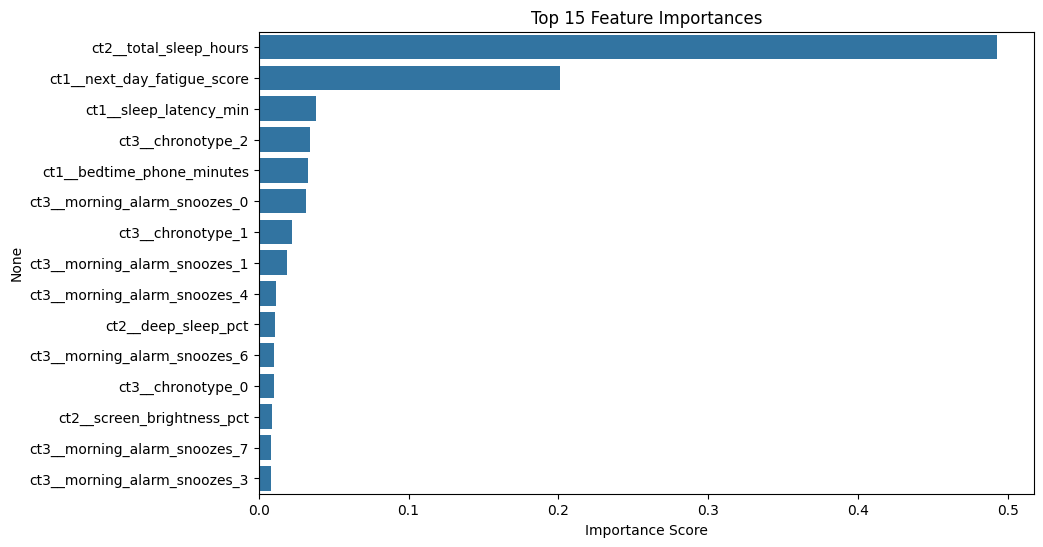

In [20]:
names = ct.get_feature_names_out()
importances = pd.Series(model.feature_importances_, index=names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.head(15), y=importances.head(15).index)
plt.title("Top 15 Feature Importances")
plt.xlabel("Importance Score")
plt.show()

In [19]:
model  = RandomForestClassifier(min_samples_split=5,n_estimators=200)
model.fit(x_train_ct,y_train)


print(classification_report(y_test,model.predict(x_test_ct)))
print("ROC AUC SCORE : " ,roc_auc_score(y_test,model.predict_proba(x_test_ct),multi_class="ovr"))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       499
           1       1.00      1.00      1.00      1095
           2       1.00      1.00      1.00       317
           3       0.97      0.99      0.98       152

    accuracy                           1.00      2063
   macro avg       0.99      1.00      0.99      2063
weighted avg       1.00      1.00      1.00      2063

ROC AUC SCORE :  0.9999925460299854
